# 04 - Supervised LSTM Log Anomaly Detection

โมเดลนี้เป็น LSTM แบบ supervised ระดับ session: ใช้ `Sequence` และ `Label` ของ HDFS เพื่อทำนายว่า session เป็น Normal (0) หรือ Anomaly (1)

ขั้นตอน: โหลดข้อมูล -> สร้าง vocabulary -> train ด้วย class-weighted BCEWithLogitsLoss -> เลือก threshold จาก validation F1 -> ประเมิน test -> บันทึกผลลัพธ์


## 1. Import libraries และตั้งค่า

In [14]:
from pathlib import Path
import json
import random
import time
from typing import Dict, Iterable, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
BATCH_SIZE = 256
EMBEDDING_DIM = 32
HIDDEN_DIM = 64
NUM_LAYERS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.001
NUM_EPOCHS = 10
PAD_ID = 0
UNK_ID = 1

DATA_DIR = Path("..") / "data" / "processed" / "HDFS"
RESULT_DIR = Path("..") / "results" / "metrics"
FIGURE_DIR = Path("..") / "results" / "figures"
CHECKPOINT_DIR = Path("..") / "checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = SEED) -> None:
    """Set reproducible random seeds for Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print(f"[1/8] Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")


[1/8] Device: cuda
GPU: NVIDIA GeForce RTX 5070
VRAM: 11.9 GB


## 2. โหลดและตรวจสอบข้อมูลแบบ labeled session

In [15]:
def load_dataset(path: Path) -> pd.DataFrame:
    """Load one processed HDFS split and report a clear missing-file error."""
    if not path.is_file():
        raise FileNotFoundError(f"ไม่พบไฟล์: {path}")
    return pd.read_csv(path)

def validate_dataset(frame: pd.DataFrame, name: str) -> None:
    """Validate session identifiers, sequences, and binary labels."""
    required = {"BlockId", "Sequence", "Label"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"{name} ขาด columns: {sorted(missing)}")
    if frame[list(required)].isna().any().any():
        raise ValueError(f"{name} มีค่า null")
    if not set(frame["Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name} Label ต้องเป็น 0 หรือ 1")
    if frame["Sequence"].astype(str).str.strip().eq("").any():
        raise ValueError(f"{name} มี Sequence ว่าง")

started = time.perf_counter()
train = load_dataset(DATA_DIR / "train.csv")
validation = load_dataset(DATA_DIR / "val.csv")
test = load_dataset(DATA_DIR / "test.csv")
for name, frame in (("train", train), ("validation", validation), ("test", test)):
    validate_dataset(frame, name)
    print(f"{name}: {len(frame):,} sessions | Normal={int((frame.Label == 0).sum()):,} | "
          f"Anomaly={int((frame.Label == 1).sum()):,}")
print(f"[2/8] โหลดข้อมูลเสร็จใน {time.perf_counter() - started:.1f} วินาที")


train: 402,542 sessions | Normal=390,755 | Anomaly=11,787
validation: 86,259 sessions | Normal=83,734 | Anomaly=2,525
test: 86,260 sessions | Normal=83,734 | Anomaly=2,526
[2/8] โหลดข้อมูลเสร็จใน 0.3 วินาที


## 3. สร้าง vocabulary และ encode sequences

In [16]:
def create_vocabulary(frames: Iterable[pd.DataFrame]) -> Tuple[Dict[str, int], Dict[int, str]]:
    """Create an event vocabulary from training data with PAD=0 and UNK=1."""
    events = sorted({event for frame in frames for sequence in frame["Sequence"]
                     for event in str(sequence).split()})
    event_to_id = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
    event_to_id.update({event: index for index, event in enumerate(events, start=2)})
    return event_to_id, {index: event for event, index in event_to_id.items()}

def encode_events(sequence: str, event_to_id: Dict[str, int]) -> List[int]:
    """Encode event names and map unseen validation/test events to UNK."""
    return [event_to_id.get(event, UNK_ID) for event in str(sequence).split()]

event_to_id, id_to_event = create_vocabulary((train,))
print(f"[3/8] Vocabulary size: {len(event_to_id):,}")
print(f"Example mapping: {list(event_to_id.items())[:8]}")


[3/8] Vocabulary size: 47
Example mapping: [('<PAD>', 0), ('<UNK>', 1), ('E1', 2), ('E10', 3), ('E11', 4), ('E12', 5), ('E13', 6), ('E14', 7)]


## 4. สร้าง Dataset และ DataLoader ระดับ session

In [17]:
class SessionDataset(Dataset):
    """Dataset of variable-length encoded event sequences and session labels."""
    def __init__(self, frame: pd.DataFrame, event_to_id: Dict[str, int]) -> None:
        self.sequences = [encode_events(value, event_to_id) for value in frame["Sequence"]]
        self.labels = frame["Label"].astype(np.float32).tolist()

    def __len__(self) -> int:
        """Return the number of sessions."""
        return len(self.labels)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor]:
        """Return one encoded session and its binary label."""
        return (torch.tensor(self.sequences[index], dtype=torch.long),
                torch.tensor(self.labels[index], dtype=torch.float32))

def collate_sessions(batch: Sequence[Tuple[torch.Tensor, torch.Tensor]]) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Pad a batch of sessions and return sequences, lengths, and labels."""
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    return padded, lengths, torch.stack(labels)

train_dataset = SessionDataset(train, event_to_id)
validation_dataset = SessionDataset(validation, event_to_id)
test_dataset = SessionDataset(test, event_to_id)
loader_args = {"batch_size": BATCH_SIZE, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
train_loader = DataLoader(train_dataset, shuffle=True, collate_fn=collate_sessions, **loader_args)
validation_loader = DataLoader(validation_dataset, shuffle=False, collate_fn=collate_sessions, **loader_args)
test_loader = DataLoader(test_dataset, shuffle=False, collate_fn=collate_sessions, **loader_args)
print(f"[4/8] Session batches: train={len(train_loader):,}, validation={len(validation_loader):,}, test={len(test_loader):,}")


[4/8] Session batches: train=1,573, validation=337, test=337


## 5. สร้าง supervised session-level LSTM

In [18]:
class SessionLSTM(nn.Module):
    """LSTM classifier that predicts one anomaly logit per session."""
    def __init__(self, vocabulary_size: int, embedding_dim: int, hidden_dim: int,
                 num_layers: int, dropout: float) -> None:
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, inputs: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        """Return one raw anomaly logit per input session."""
        embedded = self.embedding(inputs)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(hidden[-1]).squeeze(1)

negative_count = int((train["Label"] == 0).sum())
positive_count = int((train["Label"] == 1).sum())
pos_weight = torch.tensor([negative_count / max(1, positive_count)], dtype=torch.float32, device=DEVICE)
model = SessionLSTM(len(event_to_id), EMBEDDING_DIM, HIDDEN_DIM, NUM_LAYERS, DROPOUT).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(f"[5/8] Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")
print(f"Class weight for Anomaly: {pos_weight.item():.4f}")


[5/8] Parameters: 59,937
Class weight for Anomaly: 33.1514


## 6. Train ด้วย class-weighted BCEWithLogitsLoss

    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
    batch 1,256/1,573
    batch 1,570/1,573
Epoch 1/10 | train_loss=0.0774 | val_loss=0.0098 | time=34.6s
    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
    batch 1,256/1,573
    batch 1,570/1,573
Epoch 2/10 | train_loss=0.0145 | val_loss=0.0086 | time=34.2s
    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
    batch 1,256/1,573
    batch 1,570/1,573
Epoch 3/10 | train_loss=0.0076 | val_loss=0.0063 | time=33.7s
    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
    batch 1,256/1,573
    batch 1,570/1,573
Epoch 4/10 | train_loss=0.0066 | val_loss=0.0057 | time=33.8s
    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
    batch 1,256/1,573
    batch 1,570/1,573
Epoch 5/10 | train_loss=0.0089 | val_loss=0.0112 | time=34.3s
    batch 1/1,573
    batch 314/1,573
    batch 628/1,573
    batch 942/1,573
  

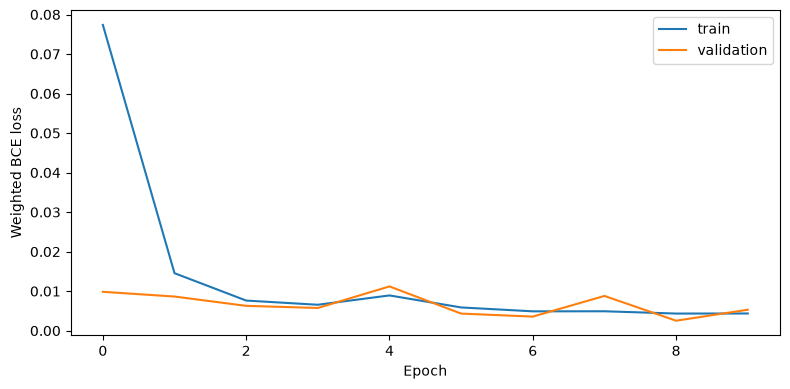

[6/8] Supervised training เสร็จแล้ว


In [19]:
def run_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module,
              optimizer: torch.optim.Optimizer | None = None) -> float:
    """Run one training or evaluation epoch and return mean loss."""
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_items = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_number, (inputs, lengths, labels) in enumerate(loader, start=1):
            inputs, lengths = inputs.to(DEVICE), lengths.to(DEVICE)
            labels = labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            loss = criterion(model(inputs, lengths), labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            total_items += len(labels)
            if training and (batch_number == 1 or batch_number % max(1, len(loader) // 5) == 0):
                print(f"    batch {batch_number:,}/{len(loader):,}", flush=True)
    return total_loss / max(1, total_items)

train_losses, validation_losses = [], []
for epoch in range(NUM_EPOCHS):
    started = time.perf_counter()
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    validation_loss = run_epoch(model, validation_loader, criterion)
    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} | train_loss={train_loss:.4f} | "
          f"val_loss={validation_loss:.4f} | time={time.perf_counter() - started:.1f}s", flush=True)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="train")
plt.plot(validation_losses, label="validation")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_lstm_training_loss.png", dpi=150)
plt.show()
print("[6/8] Supervised training เสร็จแล้ว")


## 7. เลือก threshold จาก validation F1

In [20]:
@torch.no_grad()
def predict_probabilities(model: nn.Module, loader: DataLoader, name: str) -> np.ndarray:
    """Return anomaly probabilities for all sessions in a loader."""
    model.eval()
    probabilities = []
    processed = 0
    for inputs, lengths, _ in loader:
        logits = model(inputs.to(DEVICE), lengths.to(DEVICE))
        probabilities.extend(torch.sigmoid(logits).cpu().numpy().tolist())
        processed += len(inputs)
        if processed == len(loader.dataset) or processed % 20_000 < len(inputs):
            print(f"  {name}: {processed:,}/{len(loader.dataset):,} sessions", flush=True)
    return np.asarray(probabilities, dtype=np.float64)

validation_probabilities = predict_probabilities(model, validation_loader, "validation")
thresholds = np.linspace(0.01, 0.99, 197)
validation_f1 = [f1_score(validation["Label"], validation_probabilities >= value, zero_division=0)
                 for value in thresholds]
best_index = int(np.argmax(validation_f1))
threshold = float(thresholds[best_index])
print(f"[7/8] Best validation F1: {validation_f1[best_index]:.4f}")
print(f"Validation threshold: {threshold:.4f}")


  validation: 20,224/86,259 sessions
  validation: 40,192/86,259 sessions
  validation: 60,160/86,259 sessions
  validation: 80,128/86,259 sessions
  validation: 86,259/86,259 sessions
[7/8] Best validation F1: 0.9880
Validation threshold: 0.9500


## 8. ประเมิน test และบันทึกผลลัพธ์

  test: 20,224/86,260 sessions
  test: 40,192/86,260 sessions
  test: 60,160/86,260 sessions
  test: 80,128/86,260 sessions
  test: 86,260/86,260 sessions
{
  "precision": 0.9764,
  "recall": 0.998,
  "f1_score": 0.9871,
  "pr_auc": 0.9996,
  "confusion_matrix": [
    [
      83673,
      61
    ],
    [
      5,
      2521
    ]
  ]
}


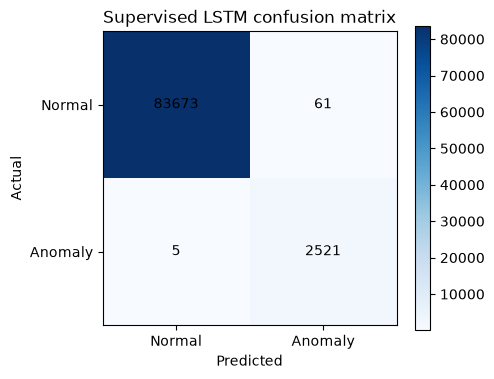

[8/8] เสร็จสมบูรณ์: checkpoint, metrics และ figures ถูกบันทึกแล้ว


In [21]:
test_probabilities = predict_probabilities(model, test_loader, "test")
test_predictions = (test_probabilities >= threshold).astype(int)
test_labels = test["Label"].to_numpy()
test_matrix = confusion_matrix(test_labels, test_predictions)
metrics = {
    "precision": round(float(precision_score(test_labels, test_predictions, zero_division=0)), 4),
    "recall": round(float(recall_score(test_labels, test_predictions, zero_division=0)), 4),
    "f1_score": round(float(f1_score(test_labels, test_predictions, zero_division=0)), 4),
    "pr_auc": round(float(average_precision_score(test_labels, test_probabilities)), 4)
    if len(np.unique(test_labels)) > 1 else None,
    "confusion_matrix": test_matrix.tolist(),
}
print(json.dumps(metrics, indent=2))

plt.figure(figsize=(5, 4))
plt.imshow(test_matrix, cmap="Blues")
plt.title("Supervised LSTM confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Normal", "Anomaly"])
plt.yticks([0, 1], ["Normal", "Anomaly"])
for row in range(2):
    for column in range(2):
        plt.text(column, row, test_matrix[row, column], ha="center", va="center")
plt.colorbar()
plt.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_DIR / "06_lstm_confusion_matrix.png", dpi=150)
plt.show()

checkpoint = {
    "model_state_dict": model.state_dict(),
    "event_to_id": event_to_id,
    "id_to_event": id_to_event,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "threshold": threshold,
    "class_weight": pos_weight.item(),
    "seed": SEED,
}
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(checkpoint, CHECKPOINT_DIR / "lstm_deeplog_hdfs.pt")

payload = {
    "model": "SupervisedSessionLSTM",
    "dataset": "HDFS",
    "train_sessions": len(train),
    "normal_train_sessions": int((train["Label"] == 0).sum()),
    "anomaly_train_sessions": int((train["Label"] == 1).sum()),
    "val_sessions": len(validation),
    "test_sessions": len(test),
    "vocabulary_size": len(event_to_id),
    "threshold": round(threshold, 4),
    "class_weight_anomaly": round(pos_weight.item(), 4),
    **metrics,
    "device": str(DEVICE),
    "seed": SEED,
    "notes": "Supervised session-level LSTM trained with labeled HDFS sequences and class-weighted BCEWithLogitsLoss; threshold selected on validation F1.",
}
RESULT_DIR.mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "lstm_deeplog_hdfs.json").write_text(
    json.dumps(payload, indent=2, allow_nan=False), encoding="utf-8"
)
print("[8/8] เสร็จสมบูรณ์: checkpoint, metrics และ figures ถูกบันทึกแล้ว")
